# Primer zadatka iz klasterizacije

U fajlu “guardian_news_subset.csv” su dati podaci o novinskim tekstovima koje je objavljivao
britanski list Guardian u toku nekoliko godina. Fajl sadrži više kolona (varijabli) od kojih su za
ovaj zadatak relevantne samo kolone `webTitle` i `bodyContent`.


Koristeći podatke iz navedenog fajla, potrebno je uraditi sledeće:


* Kreirati novu kolonu **`articleText`** koja objedinjuje sadržaj kolona webTitle i bodyContent
(kroz obično nadovezivanje stringova).


* Transformisati sadržaj kolone articleText u vektorsku (tj. numeričku) reprezentaciju
primenom pristupa zasnovanom na **`vektorima reči`** (word vectors), i konkretno vektorima
reči raspoloživim u okviru **`spaCy medium modela`**.


* Izvršiti klasterizaciju (transformisanih) novinskih tekstova primenom **`aglomerativnog
hijerarhijskog klasterovanja`**. Odrediti optimalni broj klastera na osnovu **`dendrograma`** i
**`siluet skora`** (silhouette score). Obrazložiti izbor optimalnog broja klastera.


* Za svaki od klastera odrediti **`top 10 reči / izraza`** na osnovu **`TF-IDF metrike`**.


* Odrediti **`veličinu svakog od klastera`** i **`opisati svaki klaster`** na osnovu identifikovanih top
10 reči / izraza, i eventualnog uvida u naslove / sadržaj članaka u okviru klastera.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

from sentence_transformers import SentenceTransformer

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [2]:
RAND_STATE = 1
SPACY_MODEL = 'en_core_web_md'

### Ucitavanje i priprema podataka

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'guardian_news_subset.csv')
data.head()

,id,webTitle,bodyContent,webPublicationDate
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2500 non-null   int64
 1   webTitle            2500 non-null   str  
 2   bodyContent         2483 non-null   str  
 3   webPublicationDate  2500 non-null   str  
dtypes: int64(1), str(3)
memory usage: 78.3 KB


In [5]:
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2483 non-null   int64
 1   webTitle            2483 non-null   str  
 2   bodyContent         2483 non-null   str  
 3   webPublicationDate  2483 non-null   str  
dtypes: int64(1), str(3)
memory usage: 77.7 KB


In [6]:
data.duplicated().sum()

np.int64(0)

Kreiranje kolone `articleText`

In [7]:
data['articleText'] = data.apply(lambda row: f"{row['webTitle']}. {row['bodyContent']}", axis=1)

Ispitacemo duzinu teksta, maksimalna duzina je 400 reci.

In [8]:
data['article_len_words'] = data.articleText.apply(lambda txt: len(txt.split()))
data.article_len_words.describe()

count    2483.000000
mean      803.726540
std       569.189889
min        67.000000
25%       445.000000
50%       698.000000
75%       987.000000
max      7277.000000
Name: article_len_words, dtype: float64

Redukovacemo tekstove na duzinu od 400 reci

In [9]:
def shorten_text(text):
    article_word_count = len(text.split())
    return text if article_word_count <= 400 else " ".join(text.split()[:400])

data['articleText_reduced'] = data.articleText.apply(shorten_text)

In [10]:
data.head(10)

,id,webTitle,bodyContent,webPublicationDate,articleText,article_len_words,articleText_reduced
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z,John Prine review – legendary songwriter looks...,816,John Prine review – legendary songwriter looks...
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z,Nigel Kennedy; Oxford lieder festival; London ...,1125,Nigel Kennedy; Oxford lieder festival; London ...
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z,The week in classical: BBC Proms 49 & 51; Lond...,822,The week in classical: BBC Proms 49 & 51; Lond...
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z,"Archie Shepp on jazz, race and freedom: 'Insti...",1410,"Archie Shepp on jazz, race and freedom: 'Insti..."
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z,'He was my inspiration': fans flock to George ...,1094,'He was my inspiration': fans flock to George ...
5,127210,Durand Jones & the Indications: Private Space ...,Formed out of Indiana University’s Soul Revue ...,2021-07-30T07:30:02Z,Durand Jones & the Indications: Private Space ...,255,Durand Jones & the Indications: Private Space ...
6,126303,Randall Goosby: Roots review | Erica Jeal's cl...,Roots is the debut solo disc from the young Am...,2021-06-24T14:00:02Z,Randall Goosby: Roots review | Erica Jeal's cl...,409,Randall Goosby: Roots review | Erica Jeal's cl...
7,65941,Frankie Valli and the Four Seasons review – fa...,The 77-year-old singer-songwriter David Crosby...,2018-11-29T10:48:56Z,Frankie Valli and the Four Seasons review – fa...,361,Frankie Valli and the Four Seasons review – fa...
8,40224,Marry Waterson and David A Jaycock: Death Had ...,A member of Yorkshire’s Waterson/Carthy folk d...,2017-09-24T07:00:38Z,Marry Waterson and David A Jaycock: Death Had ...,120,Marry Waterson and David A Jaycock: Death Had ...
9,28491,Orchestra Baobab: Tribute to Ndiouga Dieng rev...,When Latin styles crossed to West Africa in th...,2017-03-26T07:00:24Z,Orchestra Baobab: Tribute to Ndiouga Dieng rev...,117,Orchestra Baobab: Tribute to Ndiouga Dieng rev...


In [11]:
data['articleText_reduced'].apply(lambda txt: len(txt.split())).describe()

count    2483.000000
mean      376.239629
std        60.248032
min        67.000000
25%       400.000000
50%       400.000000
75%       400.000000
max       400.000000
Name: articleText_reduced, dtype: float64

### Transformacija komentara u numericke vektore

In [12]:
class CustomTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, spacy_pipeline, vector_dim=300):
        self.spacy_pipeline=spacy_pipeline
        self.vector_dim=vector_dim

    def fit(self, X, y=None):
        return self

    def spacy_tokenizer(self, doc):
        tokens = self.spacy_pipeline(doc)
        tokens = [token for token in tokens if
                  (not token.is_punct) and
                  (not token.is_space) and
                  (not token.is_stop) and
                  (not token.like_num) and
                  (not token.like_url)]
        words = [token.lemma_.lower() for token in tokens]
        return words

    def transform(self, X,):
        X_transformed = np.zeros((len(X), self.vector_dim))
        for i, text in enumerate(X):
            words = self.spacy_tokenizer(text)
            X_transformed[i] = self.spacy_pipeline(" ".join(words)).vector

        return X_transformed

In [13]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser','ner'])
transformer = CustomTransformer(spacy_pipeline=spacy_model)
embeddings = transformer.fit_transform(X=data.articleText_reduced)

In [14]:
embeddings.shape

(2483, 300)

### Racunanje slicnosti i klasterizacija

In [15]:
cos_dist = 1 - cosine_similarity(embeddings, embeddings)
cos_dist.shape

(2483, 2483)

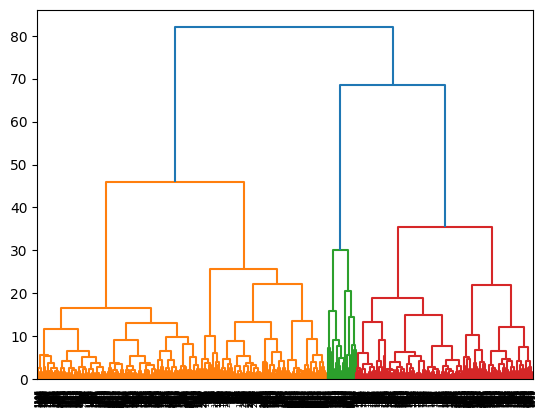

In [16]:
ward_linkage = sch.linkage(cos_dist, method='ward')

plt.figure()
sch.dendrogram(ward_linkage)
plt.show()

Na osnovu dendrograma, deluje da bi optimalan broj klastera mogao biti izmedju 2 i 5.
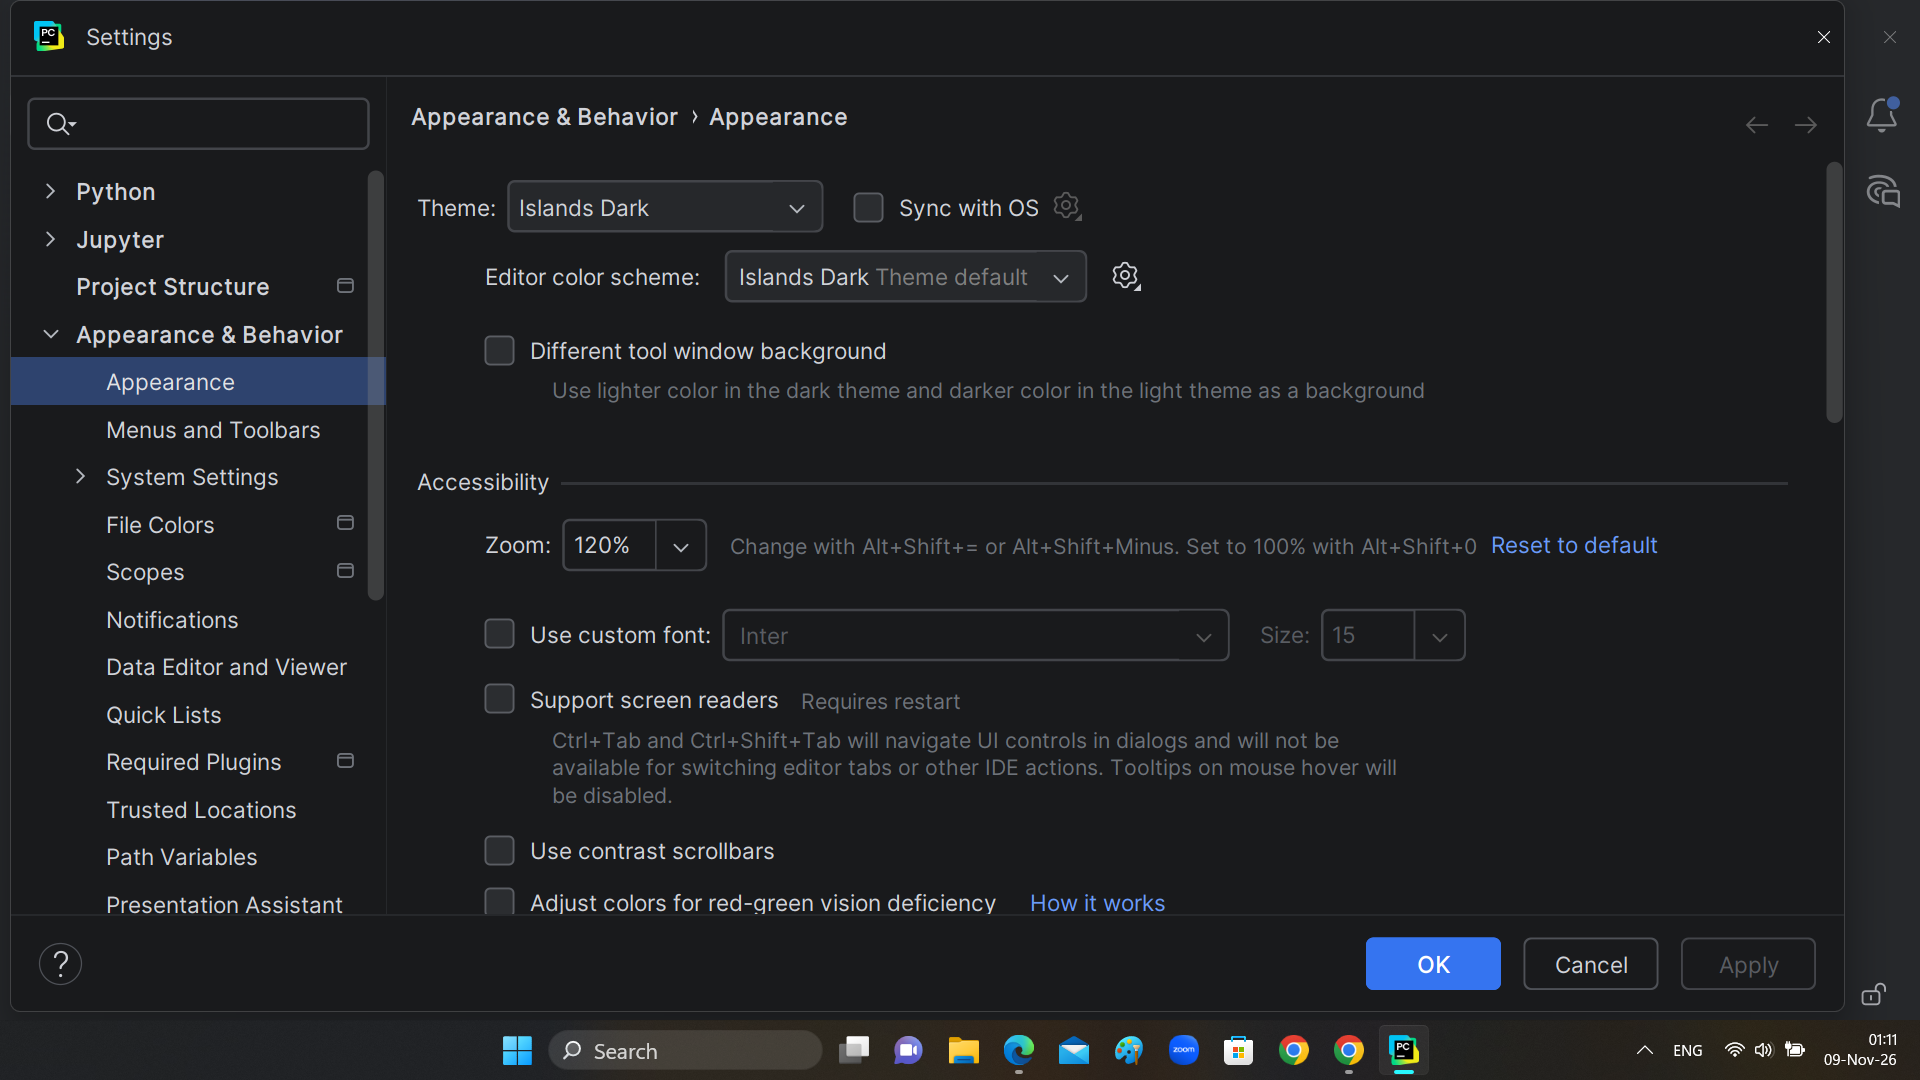

In [22]:
k_range = range(2,6)
s_scores = []

cos_dist_clipped = np.clip(cos_dist, a_min=0.0, a_max=None)

for k in k_range:
    k_clusters = sch.fcluster(ward_linkage,
                              t=k,
                              criterion='maxclust')
    score = silhouette_score(cos_dist_clipped,
                             k_clusters,
                             metric='precomputed')
    s_scores.append(score)

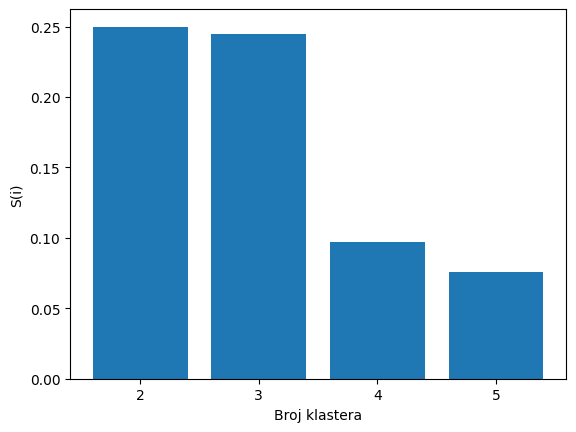

In [23]:
plt.bar(k_range, s_scores)
plt.xlabel('Broj klastera')
plt.ylabel('S(i)')
plt.xticks(k_range)
plt.show()

Na osnovu dendrograma i silhouette skora za razlicite vrednosti broja klastera, biramo resenje sa `3 klastera`. Iako resenje sa dva klastera ima nesto visu vrednost za siluetu, dendrogram vise upucuje na tri klastera, a generalno se podela na dva klastera ne preferira ako postoji priblizno dobro alternativno resenje.

In [25]:
cluster_opt = sch.fcluster(ward_linkage,
                           t=3,
                           criterion='maxclust')
data['cluster'] = cluster_opt
data.cluster.value_counts()

cluster
1    1453
3     887
2     143
Name: count, dtype: int64

Vidimo velicinu i uravnotezenost klastera.

Raspodela clanaka po klasterima nije idealno uravnotezena, jer klasteri nemaju priblizno isti broj elemenata.

### Odredjivanje kljucnih reci

In [26]:
def spacy_tokenizer(txt):
    tokens = spacy_model(txt)
    tokens = [token for token in tokens if
              (not token.is_space) and
              (not token.is_punct) and
              (not token.is_stop) and
              (not token.like_num) and
              (not token.like_url)]
    words = [token.lemma_.lower() for token in tokens]
    return words

def get_top_ngrams(cluster_id, top_n=10, words_to_remove=None):

     vectorizer = TfidfVectorizer(
         tokenizer=spacy_tokenizer,
         token_pattern=None,
         ngram_range=(1,2),
         min_df=0.01,
         max_df=0.95
     )

     cluster_reviews = data.loc[data.cluster == cluster_id, 'articleText_reduced']

     cluster_tfidf = vectorizer.fit_transform(cluster_reviews)

     candidate_keywords = vectorizer.get_feature_names_out()

     mean_tfidf = np.asarray(cluster_tfidf.mean(axis=1)).flatten()

     sorted_candidates = sorted([(keyword, tfidf) for keyword, tfidf in zip(candidate_keywords, mean_tfidf)],
                                key = lambda x: x[1],
                                reverse=True)

     if words_to_remove:
         sorted_candidates = [(kw, sc) for kw, sc in sorted_candidates
                              if kw not in words_to_remove]

     return sorted_candidates[:top_n]

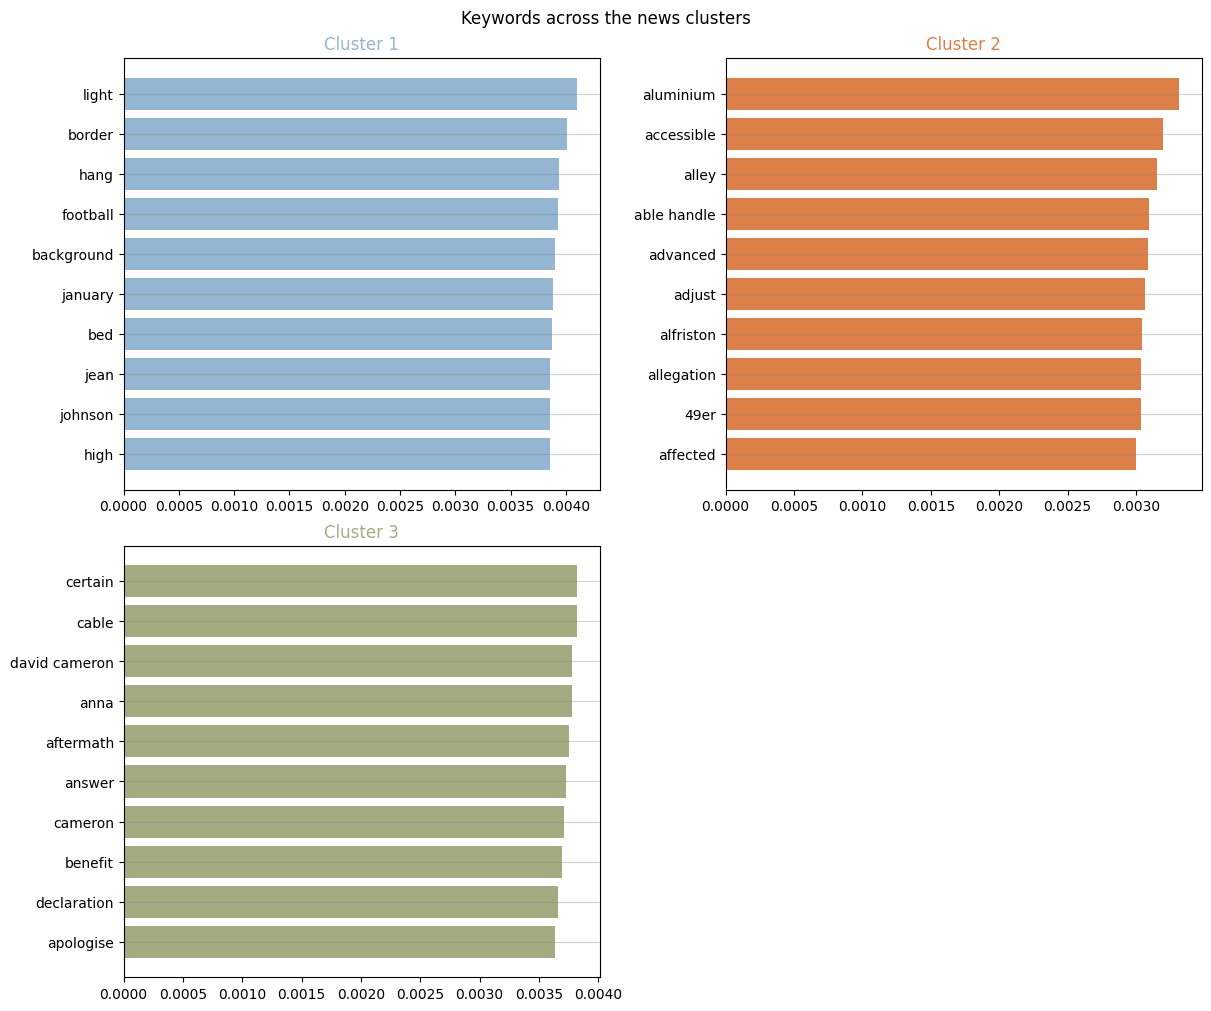

In [29]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=2, ncols=2, figsize=(12, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data['cluster'].nunique()
for i in range(n_clust):

    scored_kwds = get_top_ngrams(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

# za slucaj da je kreirano vise plotova nego sto je potrebno za prikaz (npr. grid 2x2, za prikaz 3 klastera)
axes[n_clust].remove()

fig.suptitle("Keywords across the news clusters")

plt.show()

S obzirom da tematski fokus klastera 2 nije jasan iz izvedenih kljucnih reci, pogledacemo desetak nasumicno izabranih naslova:

In [32]:
data.loc[data.cluster==2, 'webTitle'].sample(n=20, random_state=RAND_STATE)

1845    Huawei P30 Pro’s 5x optical zoom steps up phon...
2196    10 of the best seaside cafes and restaurants i...
1531     Ring the changes: the best mid-price smartphones
371     Isaac: The Time of Lorenzo de’ Medici and Maxi...
2297    Budapest's Christmas markets: winter made cosy...
1616    What are the best keyboard shortcuts for Windows?
1042                 Horse racing tips: Wednesday 29 June
1612    Bitcoin price reaches three-year high of more ...
1784    Brexit hits Apple Mac customers hard as prices...
1936    Google aims to let you block all spam calls wi...
2343            10 of the best things to do in the Azores
1682    Google: Pixel 2 XL screen burn 'should not aff...
1900    Apple accused of breaking EU law over App Stor...
1969       iPhone XR review: Apple's cheaper battery king
1529    Nvidia Shield TV review: the best Android TV b...
1165    Robin Haase’s coach arrested in connection wit...
1567    Apple warns new credit card users over risks o...
1942    Google

In [34]:
data.loc[data.cluster==1, 'webTitle'].sample(n=20, random_state=RAND_STATE)

1072    Whose idea was it? Who took the sandpaper? The...
828     EU talks going UK's way, says David Cameron on...
1996       A country diarist walks the Vale of Llangollen
978     Corbyn draws inspiration from past, present, l...
39      Mary Wilson of the Supremes: ‘Motown was like ...
1208    Rory Burns excels but falls short of maiden Te...
2240    Brilliant winter holidays in Europe: readers’ ...
101     Boyzone review – highs and lows revisited in a...
2015          The best party destinations for backpackers
1623    What is facial recognition - and how sinister ...
458     Nicolas Jaar: Sirens review – electronic noodl...
1842    Twitter users respond to 280-character limit –...
2384         Disneyland-on-Sea: a Frozen cruise to Norway
2030    A backpacker’s guide to China: a one-month iti...
1176    Tom Wood wary of England being caught out by n...
250     Lily Allen says black-cab driver told her: 'Fi...
287     Manon Lescaut review – first-rate singing but ...
151     LSO/Ra

In [36]:
data.loc[data.cluster==3, 'webTitle'].sample(n=20, random_state=RAND_STATE)

1571    Call for encryption ban pits Rudd against indu...
863     Sturgeon demands independence referendum power...
1934    Lee Kun-hee, Samsung Electronics chairman, die...
870     Brexit: government publishes bill to trigger a...
1999    Smaller Earth starts Chinese summer camp jobs ...
48      Marilyn Manson: active arrest warrant issued f...
1501    Could Donald Trump really get Apple to 'build ...
718     DWP document refers to benefit claimant as 'ly...
832     Brexit weekly briefing: customs union fast bec...
47      Spotify to pay out $112m in royalties to songw...
1678    Uber challenges ruling on drivers' rights at c...
1768    Twitter chief Jack Dorsey announces plans to m...
309     Readers recommend: share your songs about reli...
1895    Joe Rogan hosts Alex Jones on Spotify podcast ...
898     Labour: compromises, big egos and dead cats | ...
1797    Apple boss says virtual reality is 'really coo...
1540    Facebook accused by Brussels over 'patchy' att...
1332    ECB sh

Zbog niskog silhouette score-a, klasteri nisu jasno razdvojeni, pa nije ni njihov kontekst, ali bi se iz ovog pregleda moglo zakljuciti:
* klaster 1: politika, muzika i putovanja
* klaster 2: tehnologija i putovanja
* klaster 3: politika i biznis